# 03. Wskaźnik w stylu Wachty na naszych nagraniach

Stosujemy do czterech nagrań z BrainAccess dokładnie ten schemat, który ma działać w demo: **kalibracja na początku, potem z-score każdego okna względem własnej bazy** i proste reguły stanu. Sprawdzamy trzy praktyczne rzeczy:

1. Jak bardzo wynik zależy od sposobu kalibracji (pierwsze 60 s czystych okien vs baza z całego nagrania)?
2. Ile fałszywych alarmów robią artefakty ruchu i mięśni, i ile z nich usuwa odrzucanie okien?
3. Czy z samych 8 kanałów da się wykryć napięcie mięśni (kandydat na „potwierdzanie zaciśnięciem szczęki”)?

> **Brak znaczników:** nie wiemy, co kto robił, więc nie liczymy tu trafności detekcji. Epizody alfy z notebooka 01 to kandydaci wykryci z tego samego sygnału, więc porównanie z nimi jest częściowo kołowe i służy tylko do obejrzenia zachowania wskaźnika. Na końcu jest propozycja protokołu nagrania ze znacznikami, który pozwoli to zmierzyć naprawdę.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})

OUR_CH = ["F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2"]
FS = 250
WIN_S, STEP_S = 2.0, 1.0
REJECT_UV = 300          # drop 2 s windows whose peak-to-peak exceeds this (any channel)
PERSON_COLORS = {"adi": "tab:blue", "filip": "tab:orange", "rudy": "tab:green", "wojtek": "tab:red"}


def find_recordings():
    """Locate data/recordings (repo checkout, Colab upload, or fresh clone)."""
    for p in [Path("../recordings"), Path("data/recordings"), Path("recordings"), Path("/content/recordings")]:
        if list(p.glob("*raw.fif")):
            return p
    import subprocess
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/wskalecki/Heroes_of_the_brain_AI_All_IN.git", "/content/repo"],
        capture_output=True,
    )
    p = Path("/content/repo/data/recordings")
    if list(p.glob("*raw.fif")):
        return p
    raise FileNotFoundError(
        "Nie znaleziono plików *raw.fif. Wgraj je do /content/recordings (panel plików w Colabie) "
        "albo sklonuj repo (jeśli jest prywatne, trzeba tokenu)."
    )


def load_recordings(rec_dir):
    out = {}
    for f in sorted(rec_dir.glob("*raw.fif")):
        out[f.name.split("task-")[1].split("_")[0]] = mne.io.read_raw_fif(f, preload=True)
    return out


def accel_jerk(raw):
    """Smoothed magnitude of accelerometer change (a movement proxy), one value per sample."""
    a = raw.copy().pick(["Accel_x", "Accel_y", "Accel_z"]).get_data()
    j = np.sqrt((np.diff(a, axis=1) ** 2).sum(0))
    j = np.r_[j[0], j]
    return pd.Series(j).rolling(FS, center=True, min_periods=1).mean().values


def find_end_trim(raw, factor=3.0):
    """Time (s) from which movement stays high until the end (headset being taken off)."""
    j = accel_jerk(raw)
    low = np.where(j < factor * np.median(j))[0]
    return raw.times[low[-1]] if len(low) else raw.times[-1]


def clean_windows(raw8, hp_only=False):
    """Epoch a raw (8 EEG channels) into 2 s windows with 1 s step."""
    return mne.make_fixed_length_epochs(raw8, duration=WIN_S, overlap=WIN_S - STEP_S, preload=True)

from scipy.signal import welch

BANDS = {"theta": (4, 7), "alpha": (8, 12), "beta": (13, 30)}
CAL_WINDOWS = 60        # first 60 clean windows (~60 s) = calibration, like in the demo
SMOOTH = 5              # median smoothing over 5 windows
Z_SLEEPY = 2.0          # alpha_occ z above this -> "sleepy"
Z_LOAD, Z_LOAD_ALPHA = 2.0, -1.0   # theta_front z above and alpha_par z below -> "overloaded"

## 1. Tabela okien dla każdej osoby

In [2]:
def window_table(raw, t_end):
    r8 = raw.copy().pick(OUR_CH)
    ep = clean_windows(r8.copy().filter(1, 40, verbose=False).crop(0, t_end))
    eh = clean_windows(r8.copy().filter(1, None, verbose=False).crop(0, t_end))
    X = ep.get_data()
    starts = ep.events[:, 0]
    f, p = welch(X, FS, nperseg=int(WIN_S * FS), axis=-1)
    p = p * 1e12
    df_hz = f[1] - f[0]
    pw = {b: p[:, :, (f >= lo) & (f <= hi)].sum(-1) * df_hz for b, (lo, hi) in BANDS.items()}   # (win, ch)
    fh, ph = welch(eh.get_data(), FS, nperseg=int(WIN_S * FS), axis=-1)
    emg = np.log10((ph[:, :, (fh >= 60) & (fh <= 95)].mean(-1) * 1e12).mean(1))
    jerk = accel_jerk(raw)
    T = pd.DataFrame({
        "t": starts / FS,
        "theta_front": np.log10(pw["theta"][:, [0, 1]].mean(1)),
        "alpha_par": np.log10(pw["alpha"][:, [4, 5]].mean(1)),
        "alpha_occ": np.log10(pw["alpha"][:, [6, 7]].mean(1)),
        "engagement": pw["beta"].mean(1) / (pw["alpha"].mean(1) + pw["theta"].mean(1)),
        "emg": emg,
        "ptp": np.ptp(X, axis=-1).max(1) * 1e6,
        "jerk": [jerk[s:s + int(WIN_S * FS)].mean() for s in starts],
    })
    T["bad"] = T.ptp > REJECT_UV
    return T


REC = find_recordings()
raws = load_recordings(REC)
ep_csv = next(p for p in [Path("alpha-episodes.csv"), REC.parent / "analysis" / "alpha-episodes.csv"] if p.exists())
episodes = pd.read_csv(ep_csv)

tables = {n: window_table(r, find_end_trim(r)) for n, r in raws.items()}
{n: f"{len(T)} okien, {T.bad.mean() * 100:.0f}% odrzuconych" for n, T in tables.items()}

{'adi': '532 okien, 20% odrzuconych',
 'filip': '879 okien, 5% odrzuconych',
 'rudy': '533 okien, 21% odrzuconych',
 'wojtek': '508 okien, 16% odrzuconych'}

## 2. Kalibracja i z-score

Dwie metody bazy:

- **`cal60`**: średnia i odchylenie z pierwszych 60 czystych okien (tak będzie w demo, bez wiedzy o reszcie nagrania).
- **`full`**: mediana i MAD ze wszystkich czystych okien całego nagrania (optymistyczne górne ograniczenie: baza zna całą sesję).

Stan *senny*: z-score alfy potylicznej powyżej 2. Stan *przeciążony*: z-score theta czołowej powyżej 2 **i** z-score alfy ciemieniowej poniżej −1. Oba po wygładzeniu medianą z 5 okien.

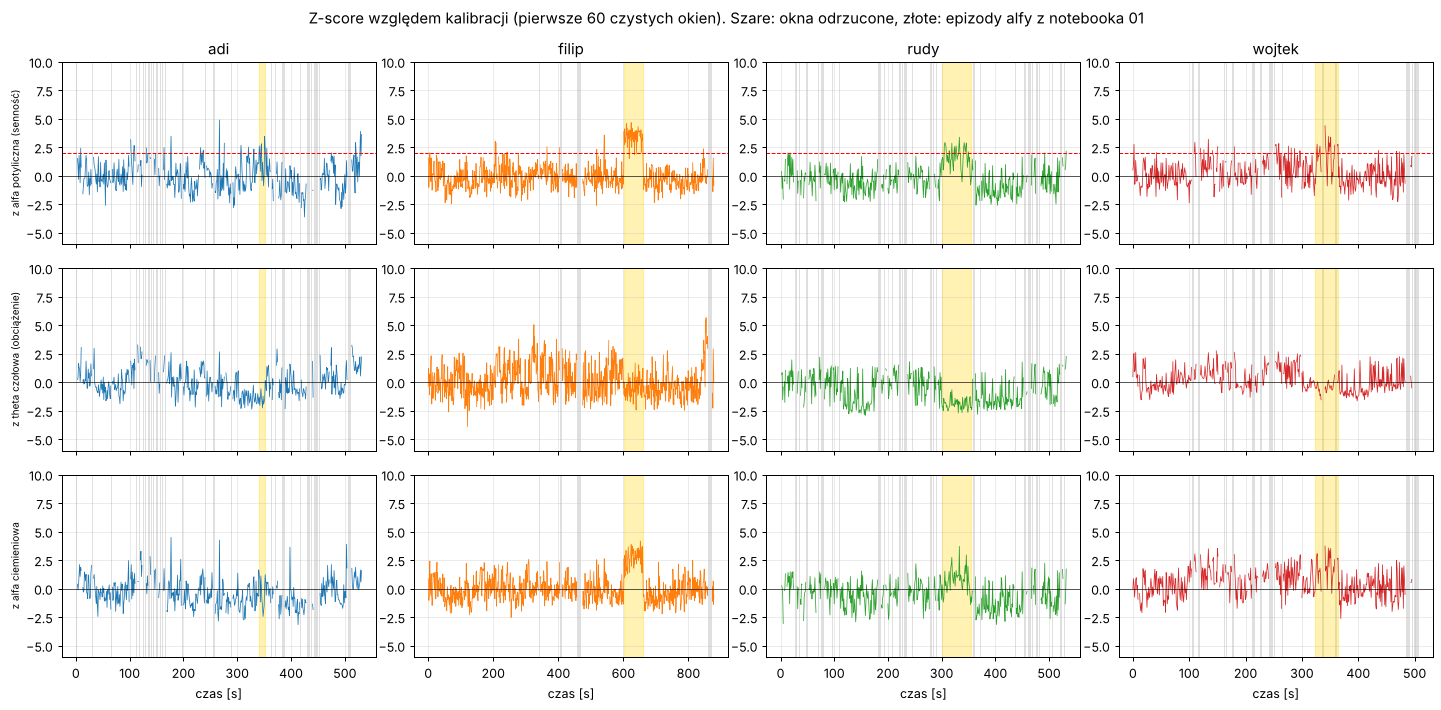

In [3]:
def add_z(T, method):
    T = T.copy()
    clean = ~T.bad
    for col in ["theta_front", "alpha_par", "alpha_occ", "engagement", "emg"]:
        if method == "cal60":
            base = T.loc[clean, col].iloc[:CAL_WINDOWS]
            mu, sd = base.mean(), base.std()
        else:
            v = T.loc[clean, col]
            mu, sd = v.median(), (v - v.median()).abs().median() * 1.4826
        T["z_" + col] = ((T[col] - mu) / sd).where(clean)
    sm = lambda s: s.rolling(SMOOTH, center=True, min_periods=1).median()
    T["sleepy"] = sm(T.z_alpha_occ) > Z_SLEEPY
    T["overload"] = (sm(T.z_theta_front) > Z_LOAD) & (sm(T.z_alpha_par) < Z_LOAD_ALPHA)
    return T


Z = {m: {n: add_z(T, m) for n, T in tables.items()} for m in ("cal60", "full")}

fig, axes = plt.subplots(3, 4, figsize=(16, 8), sharex="col")
for j, n in enumerate(tables):
    T = Z["cal60"][n]
    for i, (col, title) in enumerate([("z_alpha_occ", "z alfa potyliczna (senność)"),
                                      ("z_theta_front", "z theta czołowa (obciążenie)"),
                                      ("z_alpha_par", "z alfa ciemieniowa")]):
        ax = axes[i, j]
        ax.plot(T.t, T[col].clip(-6, 10), lw=0.6, color=PERSON_COLORS[n])
        ax.fill_between(T.t, -6, 10, where=T.bad, color="gray", alpha=0.25, lw=0)
        for a, b in episodes[episodes.osoba == n][["start [s]", "koniec [s]"]].values:
            ax.axvspan(a, b, color="gold", alpha=0.3)
        ax.axhline(0, color="k", lw=0.5)
        if i == 0:
            ax.axhline(Z_SLEEPY, color="r", ls="--", lw=0.8); ax.set_title(n)
        ax.set_ylim(-6, 10)
        if j == 0:
            ax.set_ylabel(title, fontsize=8)
    axes[2, j].set_xlabel("czas [s]")
plt.suptitle("Z-score względem kalibracji (pierwsze 60 czystych okien). Szare: okna odrzucone, złote: epizody alfy z notebooka 01")
plt.tight_layout(); plt.show()

### Wpływ sposobu kalibracji

In [4]:
rows = []
for n in tables:
    for m in ("cal60", "full"):
        T = Z[m][n]; c = ~T.bad
        rows.append(dict(osoba=n, baza=m, **{"senny [% czystego czasu]": 100 * T.sleepy[c].mean(),
                                              "przeciążony [% czystego czasu]": 100 * T.overload[c].mean()}))
R = pd.DataFrame(rows).round(1)
display(R.pivot(index="osoba", columns="baza"))

shift = {}
for n, T in tables.items():
    c = ~T.bad
    v = T.loc[c, "alpha_occ"]
    base = v.iloc[:CAL_WINDOWS]
    shift[n] = (base.mean() - v.median()) / ((v - v.median()).abs().median() * 1.4826)
pd.Series(shift, name="przesunięcie bazy cal60 względem mediany nagrania, alfa potyliczna [σ]").round(2).to_frame()

senny [% czystego czasu]      przeciążony [% czystego czasu]     
baza                      cal60 full                          cal60 full
osoba                                                                   
adi                         1.9  0.9                            0.0  0.0
filip                       7.1  7.6                            0.0  0.0
rudy                        2.9  2.6                            0.0  0.0
wojtek                      3.0  0.2                            0.0  0.0

,"przesunięcie bazy cal60 względem mediany nagrania, alfa potyliczna [σ]"
adi,0.13
filip,0.21
rudy,0.28
wojtek,-0.13


## 3. Artefakty i fałszywe alarmy

Ile okien oznaczonych jako „senny” lub „przeciążony” zniknęłoby po odrzuceniu okien z dużą amplitudą? I jak wiele z tego, co zostaje, zbiega się z ruchem głowy (akcelerometr)?

In [5]:
def flag_stats(T, use_rejection):
    T = T.copy()
    ok = ~T.bad if use_rejection else np.ones(len(T), bool)
    hi_move = T.jerk > 3 * T.jerk.median()
    out = {}
    for s in ("sleepy", "overload"):
        flagged = T[s] & ok
        out[s + " [% okien]"] = 100 * flagged.sum() / ok.sum()
        out[s + ": z ruchem [%]"] = 100 * (flagged & hi_move).sum() / max(flagged.sum(), 1)
    return out


def z_no_reject(T):
    """Same z-scoring but without dropping artifact windows (what happens if you skip rejection)."""
    T = T.copy()
    for col in ["theta_front", "alpha_par", "alpha_occ"]:
        base = T[col].iloc[:CAL_WINDOWS]
        T["z_" + col] = (T[col] - base.mean()) / base.std()
    sm = lambda s: s.rolling(SMOOTH, center=True, min_periods=1).median()
    T["sleepy"] = sm(T.z_alpha_occ) > Z_SLEEPY
    T["overload"] = (sm(T.z_theta_front) > Z_LOAD) & (sm(T.z_alpha_par) < Z_LOAD_ALPHA)
    return T


rows = []
for n in tables:
    with_rej = flag_stats(Z["cal60"][n], True)
    without = flag_stats(z_no_reject(tables[n]), False)
    rows.append({"osoba": n, "wariant": "z odrzucaniem okien", **with_rej})
    rows.append({"osoba": n, "wariant": "bez odrzucania", **without})
pd.DataFrame(rows).round(1).set_index(["osoba", "wariant"])

sleepy [% okien]  sleepy: z ruchem [%]  \
osoba  wariant                                                       
adi    z odrzucaniem okien               1.9                   0.0   
       bez odrzucania                    2.1                  54.5   
filip  z odrzucaniem okien               7.1                   5.1   
       bez odrzucania                    8.8                  26.0   
rudy   z odrzucaniem okien               2.9                   0.0   
       bez odrzucania                    2.4                   7.7   
wojtek z odrzucaniem okien               3.0                   0.0   
       bez odrzucania                    7.9                  30.0   

                            overload [% okien]  overload: z ruchem [%]  
osoba  wariant                                                          
adi    z odrzucaniem okien                 0.0                     0.0  
       bez odrzucania                      0.0                     0.0  
filip  z odrzucaniem okien                 0.0                     0.0  
       bez odrzucania                      0.0                     0.0  
rudy   z odrzucaniem okien                 0.0                     0.0  
       bez odrzucania                      0.0                     0.0  
wojtek z odrzucaniem okien                 0.0                     0.0  
       bez odrzucania                      0.0                     0.0

## 4. Czy da się wykryć napięcie mięśni? (kandydat na „zaciśnięcie szczęki”)

Napięcie mięśni (EMG) daje szerokopasmową moc w wysokich częstotliwościach. Liczymy moc 60–95 Hz (unikamy 50 Hz), normalizujemy w osobie i szukamy krótkich wybuchów. Zaciśnięcie szczęki to ruch mięśni, ale **nie głowy**, więc interesują nas wybuchy EMG przy niskim ruchu akcelerometru. Bez znaczników to tylko lista kandydatów do ręcznego sprawdzenia.

,wybuchy,mediana_dlugosc_s,bez_ruchu_glowy
osoba,,,
adi,5,4.0,1
filip,6,4.0,4
rudy,2,4.0,1
wojtek,1,7.0,1


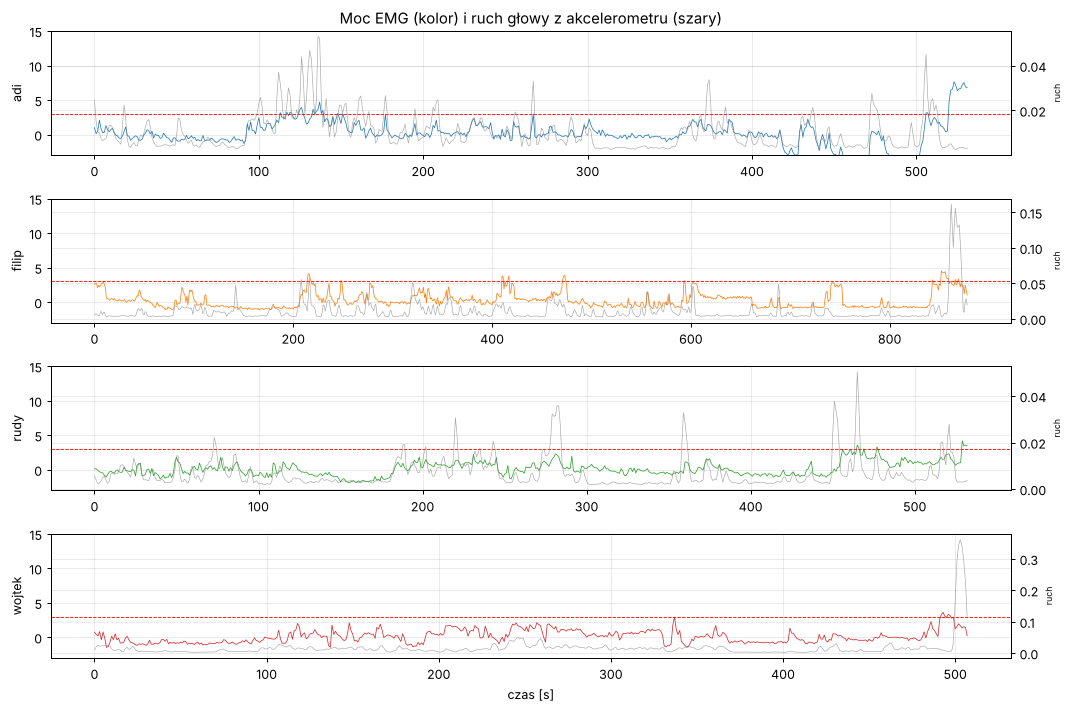

,osoba,start,dlugosc_s,ruch_glowy,ptp_max
4,adi,520,13,False,216
7,filip,416,3,False,351
8,filip,471,5,False,393
9,filip,593,3,False,117
10,filip,852,9,False,195
12,rudy,529,5,False,332
13,wojtek,492,7,False,445


In [6]:
EMG_Z = 3.0
events = []
for n, T in tables.items():
    z = (T.emg - T.emg.median()) / ((T.emg - T.emg.median()).abs().median() * 1.4826)
    on = z.rolling(3, center=True, min_periods=1).median() > EMG_Z
    start = None
    for i, v in enumerate(np.r_[on.values, False]):
        if v and start is None:
            start = i
        if not v and start is not None:
            seg = T.iloc[start:i]
            events.append(dict(osoba=n, start=round(seg.t.iloc[0]), dlugosc_s=round(seg.t.iloc[-1] - seg.t.iloc[0] + WIN_S),
                               ruch_glowy=bool(seg.jerk.mean() > 3 * T.jerk.median()), ptp_max=round(seg.ptp.max())))
            start = None
EV = pd.DataFrame(events)
display(EV.groupby("osoba").agg(wybuchy=("start", "size"), mediana_dlugosc_s=("dlugosc_s", "median"),
                                bez_ruchu_glowy=("ruch_glowy", lambda s: int((~s).sum()))))

fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=False)
for ax, (n, T) in zip(axes, tables.items()):
    z = (T.emg - T.emg.median()) / ((T.emg - T.emg.median()).abs().median() * 1.4826)
    ax.plot(T.t, z, lw=0.6, color=PERSON_COLORS[n], label="EMG 60–95 Hz (z)")
    ax2 = ax.twinx(); ax2.plot(T.t, T.jerk, lw=0.5, color="gray", alpha=0.7); ax2.set_ylabel("ruch", fontsize=7)
    ax.axhline(EMG_Z, color="r", ls="--", lw=0.7); ax.set_ylabel(n); ax.set_ylim(-3, 15)
axes[0].set_title("Moc EMG (kolor) i ruch głowy z akcelerometru (szary)")
axes[-1].set_xlabel("czas [s]")
plt.tight_layout(); plt.show()
EV[~EV.ruch_glowy].head(20)

## Co nagrać następnym razem (protokół ze znacznikami)

Żeby zamienić powyższe obserwacje w liczby trafności, potrzebujemy znaczników. Proponowany skrypt jednej sesji (ok. 8 minut), z zapisem czasu każdego kroku:

| Krok | Czas | Po co |
|---|---|---|
| Oczy otwarte, patrzenie w punkt | 60 s | baza i kalibracja |
| Oczy zamknięte | 60 s | alfa potyliczna, „senność” |
| Oczy otwarte | 30 s | powrót do bazy |
| Liczenie w pamięci (np. odejmowanie 7 od 1000) | 60 s | obciążenie |
| Spokój | 30 s | powrót |
| 10 wolnych mrugnięć, potem 10 szybkich | 30 s | czy mrugnięcia widać na F3/F4 |
| 5 zaciśnięć szczęki po 1 s, w odstępach 5 s | 30 s | „przycisk” szczęką |
| Ruch głowy w lewo i prawo, 5 razy | 20 s | test odporności na ruch |

Znaczniki: najprościej mały skrypt, który po naciśnięciu Enter zapisuje do CSV czas od startu nagrania i nazwę kroku, wyrównany z kolumną `time` w pliku nagrania. Wtedy każdy z powyższych kroków będzie miał prawdziwą etykietę.

## Wnioski

- **Wskaźnik senności działa na naszych danych:** z-score alfy potylicznej względem 60 s kalibracji rośnie do ok. 3–4 σ w epizodach alfy u wszystkich czterech osób. Porównanie jest częściowo kołowe (epizody wykryto z podobnej miary), więc to pokazuje zachowanie wskaźnika, a nie trafność.
- **Sposób kalibracji ma znaczenie, gdy sygnał jest słaby.** Baza z pierwszych 60 s odbiega od mediany całego nagrania o 0,13–0,28 σ. Odsetek czasu oznaczonego jako „senny” wychodzi 1,9 / 7,1 / 2,9 / 3,0% (Adi, Filip, Rudy, Wojtek) przy kalibracji 60 s i 0,9 / 7,6 / 2,6 / 0,2% przy bazie z całej sesji. Duża różnica jest tylko u Wojtka, u którego epizod jest słaby na tle szumu.
- **Odrzucanie artefaktów jest konieczne.** Bez niego u Wojtka odsetek flag „senny” rośnie z 3,0% do 7,9%, a duża część flag zbiega się z ruchem głowy (Adi 55%, Wojtek 30%, Filip 26%; po odrzuceniu okien 0–5%).
- **Reguła „przeciążony” nie zadziałała ani razu** (0% u wszystkich). Prawdopodobnie nikt nie wykonywał zadania obciążającego, ale reguła i tak jest niepewna (patrz notebook 02: w MATB alfa ciemieniowa rośnie zamiast spadać).
- **Napięcie mięśni:** wykryliśmy łącznie 14 wybuchów EMG (1–6 na osobę), z czego tylko 7 bez wyraźnego ruchu głowy. EMG wyraźnie współgra z ruchem, więc bez znaczników nie da się potwierdzić, że to zaciśnięcia szczęki. Pomysł „potwierdzanie szczęką” wymaga nagrania z protokołem (patrz wyżej).